# AI Part 1 (healthcare version): Search and Constraint Satisfaction
**Provider Network Access and Cost Planner** · David Satizabal · CAI4505C Artificial Intelligence

This rebuilds Part 1 on the healthcare scenario. The planner is a rational agent that assigns health plan members to in-network doctors.

- **A\* search** (the GPS) measures each member's travel miles to each doctor on a county grid where 1 cell = 1 mile.
- **Constraint satisfaction** (the wedding seating chart) decides which doctor each member gets, without going over any doctor's open slots or high-cost cap.

**PEAS**
- **Performance:** share of members placed inside the CMS distance standard (goal 90%), average miles, open-slot use, high-cost members spread under each cap, search effort
- **Environment:** county grid, provider directory, open new-patient slots
- **Actuators:** member to doctor assignments, or an access-gap flag for the network team
- **Sensors:** provider directory, open slots, member home locations, A\* miles

All data is synthetic and seeded (seed 42). **Which members count as high-cost comes from MI Part 2:** its balanced logistic regression flags the riskiest 10% (60 of the 600 members). The planner reads that file (`data/predicted_high_cost_flags.csv`) instead of the made-up flag it started with.

**To run in Colab:** run the first cell. If the project folder is not found, it clones the class repo, or asks you to upload `AI_Part1_Search_CSP.zip`.

In [1]:
# Find the project folder. If it's missing: clone the class repo, and if that fails, ask for the zip
import sys, os, zipfile, subprocess
from pathlib import Path

FOLDER = "AI_Part1_Search_CSP"
CANDIDATES = [Path.cwd(), Path.cwd() / FOLDER, Path("/content") / FOLDER,
              Path("/content/Artificial-Intelligence-Class") / FOLDER]
find = lambda: next((p for p in CANDIDATES if (p / "src" / "run_part1.py").exists()), None)
PROJECT = find()

if PROJECT is None and Path("/content").exists():
    subprocess.run(["git", "clone", "-q", "-b", "finalProject", "https://github.com/DASatizabal/Artificial-Intelligence-Class",
                    "/content/Artificial-Intelligence-Class"])
    PROJECT = find()

if PROJECT is None:
    try:
        from google.colab import files
        print(f"Project folder not found. Upload {FOLDER}.zip")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        PROJECT = find()
    except ImportError:
        raise FileNotFoundError(f"Put this notebook inside the {FOLDER} folder, or run it in Colab.")

os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
print("Project folder:", PROJECT.name)

Project folder: AI_Part1_Search_CSP


This cell finds the project files. In Colab it clones the class repo (finalProject branch), and if that fails it asks for a zip upload, so nothing crashes.

In [2]:
import pandas as pd, json
import gen_members
gen_members.main()     # rebuilds the members and open slots from seed 42
members = pd.read_csv("data/members.csv", dtype={"zip": str})
slots = pd.read_csv("data/kb/provider_slots.csv")
display(members.head())
display(slots[slots.new_slots > 0].head())

600 members (10.7% high-cost) | open slots by specialty:
                    demand  slots
cardiology              45     52
dermatology             38     44
endocrinology           41     48
ob-gyn                  49     57
orthopedic surgery      54     63
primary care           321    370
psychiatry              52     60


,member_id,zip,row,col,age,need_specialty,high_cost
0,M0001,33156,29,20,70,endocrinology,1
1,M0002,33030,36,8,60,ob-gyn,0
2,M0003,33014,16,16,71,dermatology,0
3,M0004,33015,15,15,43,cardiology,0
4,M0005,33176,29,11,54,primary care,0


,provider_id,new_slots,high_cost_cap,group
0,P0001,19,7,The Hammocks Medical Group
3,P0004,8,3,Hialeah Medical Group
4,P0005,20,7,The Hammocks Medical Group
7,P0008,19,7,Plantation Medical Group
9,P0010,20,7,Hollywood Medical Group


There are 600 members. Each has a home location near one of 16 South Florida ZIP codes, the type of doctor they need (about half need primary care), an age, and a made-up starter high-cost flag (10.7% of members). When the planner runs, that starter flag is swapped for MI Part 2's prediction (60 members, 10%). The two lists only share 10 members, so the swap changes who the planner treats as a heavy patient. Only in-network doctors who accept new patients get open slots this month. Slots add up to 115% of demand in each specialty, so the puzzle is tight. Each doctor can take high-cost members for at most 35% of its slots.

In [3]:
import run_part1
run_part1.main()
m = json.load(open("outputs/metrics.json"))
search = pd.read_csv("outputs/search_comparison.csv")
display(pd.DataFrame(m["search_totals"])[["method", "nodes", "backtracks", "specialties_solved"]])

high-cost flag source: MI Part 2 prediction (balanced logistic regression, riskiest 10%) | flagged: 60


{
 "members": 600,
 "placed": 465,
 "share_placed_within_standard": 0.775,
 "distance_gaps": 77,
 "capacity_gaps": 58,
 "avg_miles": 4.85,
 "max_miles": 15,
 "slot_use": 0.67,
 "high_cost_cap_violations": 0,
 "capacity_violations": 0
}
         specialty  members  placed_within_standard  share  meets_90pct  distance_gaps  capacity_gaps
        cardiology       45                      41 0.9111         True              1              3
       dermatology       38                      29 0.7632        False              8              1
     endocrinology       41                      41 1.0000         True              0              0
            ob-gyn       49                      44 0.8980        False              5              0
orthopedic surgery       54                      44 0.8148        False              8              2
      primary care      321                     228 0.7103        False             46             47
        psychiatry       52                      3

,method,nodes,backtracks,specialties_solved
0,Backtracking + forward checking,481019,341552,5
1,MRV + FC + LCV,200354,142385,6
2,MRV + FC + look-ahead,479,0,7
3,MRV + forward checking,200306,160764,6
4,Plain backtracking,552382,552029,5


This is the same comparison as the Unit 5 course scheduling lab. Each method got the same 7 specialty puzzles and a limit of 200,000 search steps per puzzle.

- **Plain backtracking** solved 5 of 7 and used 552,382 steps.
- **Forward checking** cut wasted steps but still failed on primary care and cardiology.
- **MRV + forward checking** (seat the pickiest member first, cross off full doctors) solved everything except primary care.
- **LCV** (try the doctor that blocks the fewest other people) did not help.
- **MRV + forward checking + look-ahead** solved all 7 in 479 steps with zero backtracks.

In [4]:
display(search[search.specialty == "primary care"][["method", "members", "nodes", "backtracks", "solved"]])

,method,members,nodes,backtracks,solved
25,Plain backtracking,228,200000,199878,False
26,Backtracking + forward checking,228,200000,145126,False
27,MRV + forward checking,228,200000,160716,False
28,MRV + FC + LCV,228,200000,142307,False
29,MRV + FC + look-ahead,228,239,0,True


Primary care is where the simple methods break. Forward checking only notices when **one** member has no seat left. It can't see when a **group** of members is competing for too few seats, so the search walks deep into a dead end and keeps undoing. The look-ahead asks one extra question before each choice: *can everyone still waiting fit into the seats that are left?* A max-flow calculation answers that exactly. With it, the search never needs to undo a choice.

**Why not AC-3?** AC-3 checks constraints between **pairs** of variables. A capacity limit involves **every** member who might pick that doctor, so it's not a pair constraint. The look-ahead is the tool that fits this kind of rule.

In [5]:
by = pd.DataFrame(m["baseline"]["by_specialty"])
display(by)
print({k: v for k, v in m["baseline"].items() if k != "by_specialty"})

,specialty,members,placed_within_standard,share,meets_90pct,distance_gaps,capacity_gaps
0,cardiology,45,41,0.9111,True,1,3
1,dermatology,38,29,0.7632,False,8,1
2,endocrinology,41,41,1.0000,True,0,0
3,ob-gyn,49,44,0.8980,False,5,0
4,orthopedic surgery,54,44,0.8148,False,8,2
5,primary care,321,228,0.7103,False,46,47
6,psychiatry,52,38,0.7308,False,9,5


{'members': 600, 'placed': 465, 'share_placed_within_standard': 0.775, 'distance_gaps': 77, 'capacity_gaps': 58, 'avg_miles': 4.85, 'max_miles': 15, 'slot_use': 0.67, 'high_cost_cap_violations': 0, 'capacity_violations': 0}


The planner placed **465 of 600 members (77.5%)** inside the CMS distance standard, at an average of 4.85 miles. No doctor went over capacity or over the high-cost cap. Only cardiology and endocrinology met the 90% standard.

The other 135 members are the most useful output for a network team:
- **77 distance gaps:** no in-network doctor accepting patients is inside the standard at all. The fix is recruiting.
- **58 capacity gaps:** doctors are close enough but already full. The fix is more slots.

Primary care is the worst at 71%, because its standard is only 5 miles.

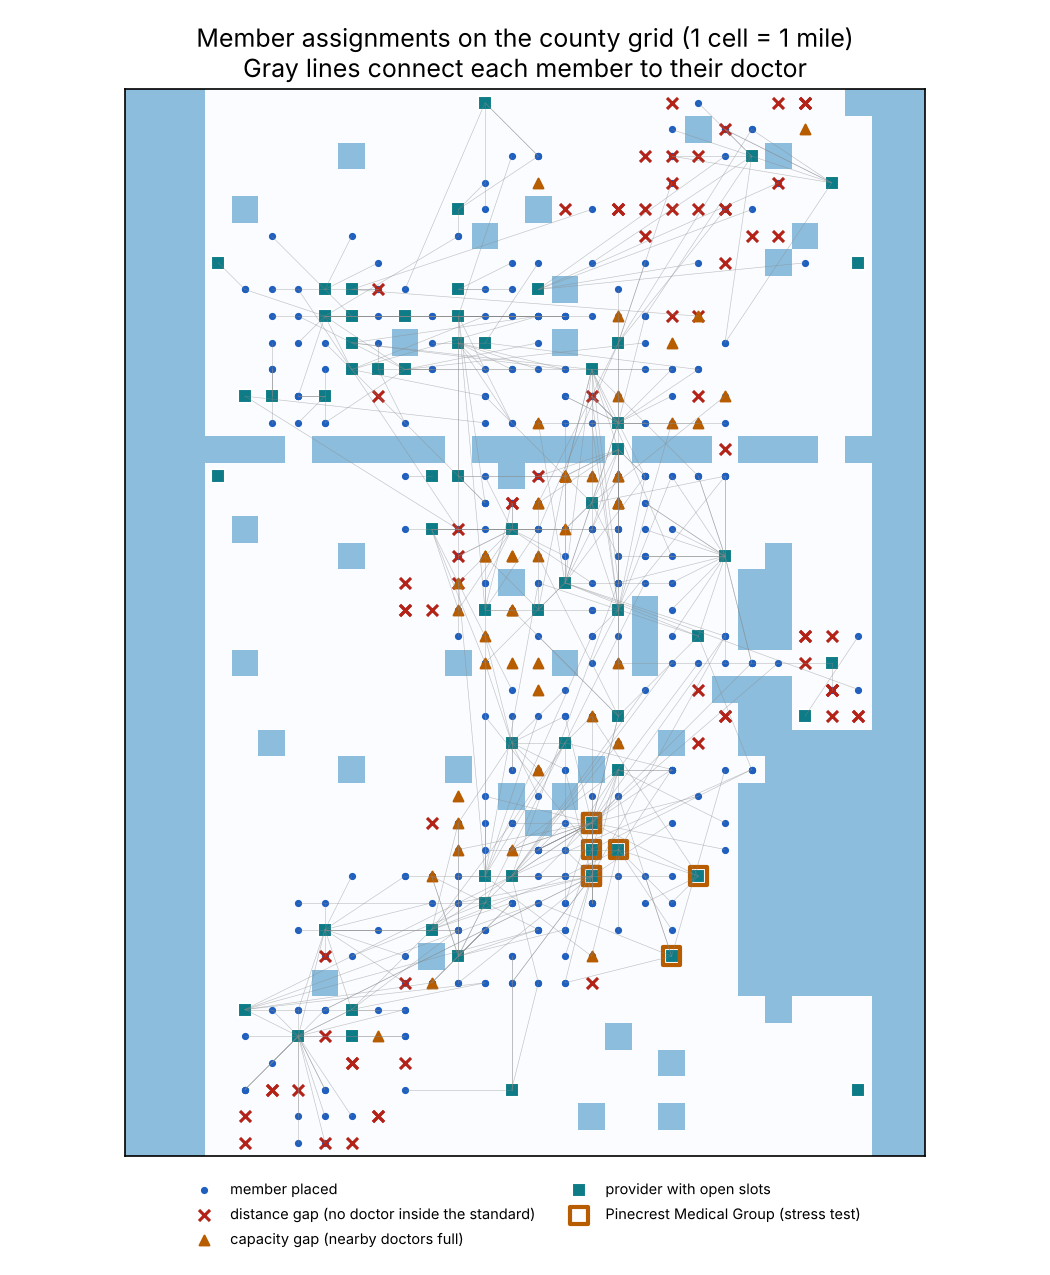

In [6]:
from IPython.display import Image
Image("outputs/assignment_map.png")

Gray lines connect each member to their doctor. Red X marks are distance gaps, clustered in the northeast and around the bay where doctors are scarce. Orange triangles are capacity gaps. The orange squares are the provider group removed in the stress test below.

In [7]:
print(json.dumps(m["stress_test"], indent=1))

{
 "group_removed": "Pinecrest Medical Group",
 "providers_removed": 15,
 "min_conflicts": {
  "steps": 3000,
  "displaced": 73,
  "displaced_replaced": 21,
  "waitlisted": 64,
  "other_members_moved": 16
 },
 "full_resolve": {
  "other_members_moved": 20,
  "placed": 402
 },
 "unaffected_members": {
  "min_conflicts_lost_doctor": 12,
  "min_conflicts_switched_doctor": 4,
  "full_resolve_lost_doctor": 12,
  "full_resolve_switched_doctor": 8
 },
 "after_min_conflicts": {
  "placed": 401,
  "share_placed_within_standard": 0.6683,
  "avg_miles": 4.87,
  "capacity_violations": 0
 },
 "after_full_resolve": {
  "placed": 402,
  "share_placed_within_standard": 0.67,
  "avg_miles": 4.98,
  "capacity_violations": 0
 }
}


**Stress test: a big provider group leaves.** The planner removes the group that serves the most members (Pinecrest Medical Group, 15 doctors), which displaces 73 members. It then compares two ways to recover:

| Way to recover | Placed afterward | Unaffected members who lost their doctor | Unaffected members switched to another doctor |
|---|---|---|---|
| Min-conflicts repair (fix only what broke) | 401 | 12 | 4 |
| Solve again from scratch | 402 | 12 | 8 |

Both end with almost the same coverage. Repair disturbs slightly fewer people who were never affected (16 vs 20 in total), and every move is a member forced to change doctors.

Two honest notes:
- **Neither method is free.** Because there aren't enough open seats near Pinecrest, both bump some unaffected members off their doctor (to the waitlist) to make room for displaced members who live closer.
- **Min-conflicts never fully settled.** It used its whole 3,000-step budget because members kept getting bumped back and forth. The final clean-up waitlists the farthest member at any full doctor, so nothing ends over capacity.

**Summary.** A\* gives exact travel miles, and the Manhattan lower bound skips doctors that can't be close enough. Constraint satisfaction with MRV, forward checking, and a max-flow look-ahead assigns 77.5% of members with no rule broken, and the planner turns everyone else into a specific, fixable access gap.